In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller 
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
df = sns.load_dataset("flights")
df.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [5]:
df.describe()

,year,passengers
count,144.000000,144.000000
mean,1954.500000,280.298611
std,3.464102,119.966317
min,1949.000000,104.000000
25%,1951.750000,180.000000
50%,1954.500000,265.500000
75%,1957.250000,360.500000
max,1960.000000,622.000000


In [12]:
df["YearMonth"]=pd.to_datetime("01-"+ df['month'].astype(str)+"-"+df['year'].astype(str))
df.set_index('YearMonth',inplace=True)
airP=df[['passengers']].copy(deep=True)
print(airP)

            passengers
YearMonth             
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121
...                ...
1960-08-01         606
1960-09-01         508
1960-10-01         461
1960-11-01         390
1960-12-01         432

[144 rows x 1 columns]


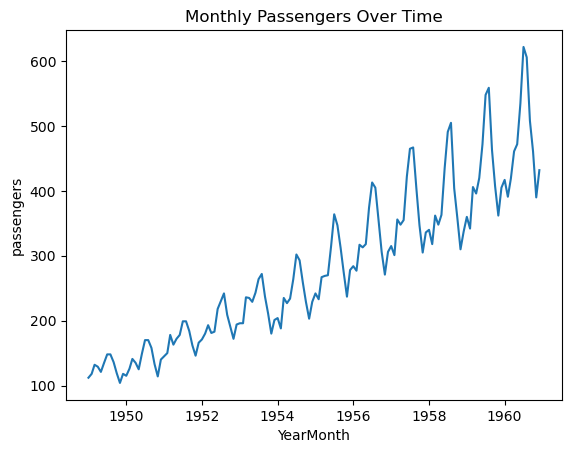

In [17]:
sns.lineplot(x=airP.index, y=airP.passengers)
plt.title("Monthly Passengers Over Time")
plt.show()

In [ ]:
#Decompose to check trend

In [20]:
# Stationary check
def test_stationary(dataframe, var, window=12):
    dataframe['rollMean'] = dataframe[var].rolling(window=window).mean()
    dataframe['rollStd'] = dataframe[var].rolling(window=window).std()
    adf_result = adfuller(dataframe[var])
    p_value = adf_result[1]

    print(f"ADF p-value : {p_value:.4f}")

    if p_value < 0.05:
        print("The time series is stationary (Reject H0)")
    else:
        print("The time series is not stationary (Failed to reject H0)")

    sns.lineplot(x=dataframe.index, y=dataframe[var], label="Original")
    sns.lineplot(x=dataframe.index, y=dataframe["rollMean"], label="Rolling Mean")
    sns.lineplot(x=dataframe.index, y=dataframe["rollStd"], label="Rolling Std")
    plt.title("Rolling Statistics")
    plt.show()

ADF p-value : 0.9919
The time series is not stationary (Failed to reject H0)


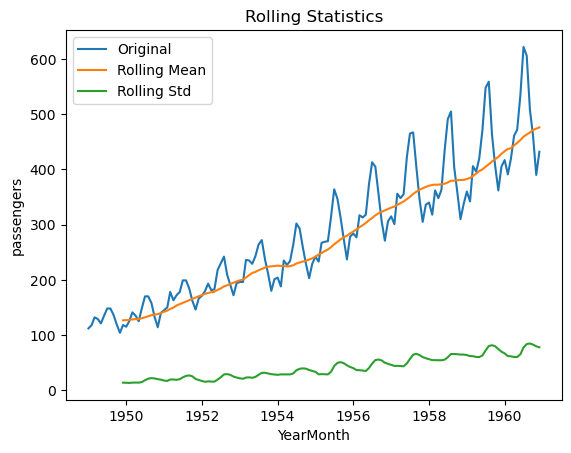

In [21]:
test_stationary(airP, 'passengers')

In [23]:
#Not stationary try with diff(1)
airP['shift']=airP.passengers.shift(1)
airP['shiftDiff']=airP['passengers']-airP["shift"]
airP.head(20)

,passengers,rollMean,rollStd,shift,shiftDiff
YearMonth,,,,,
1949-01-01,112,NaN,NaN,NaN,NaN
1949-02-01,118,NaN,NaN,112.0,6.0
1949-03-01,132,NaN,NaN,118.0,14.0
1949-04-01,129,NaN,NaN,132.0,-3.0
1949-05-01,121,NaN,NaN,129.0,-8.0
1949-06-01,135,NaN,NaN,121.0,14.0
1949-07-01,148,NaN,NaN,135.0,13.0
1949-08-01,148,NaN,NaN,148.0,0.0
1949-09-01,136,NaN,NaN,148.0,-12.0


C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_16632\2030931967.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataframe['rollMean'] = dataframe[var].rolling(window=window).mean()
C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_16632\2030931967.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataframe['rollStd'] = dataframe[var].rolling(window=window).std()


ADF p-value : 0.0707
The time series is not stationary (Failed to reject H0)


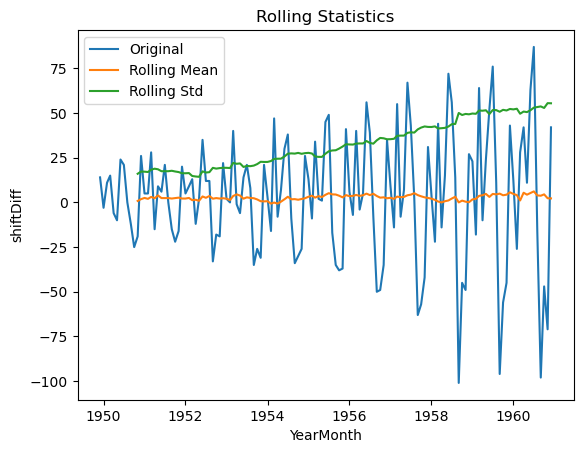

In [24]:
test_stationary(airP.dropna(),'shiftDiff')

In [25]:
airP['shift'] = airP.passengers.shift(2)
airP['shiftDiff']=airP['passengers']-airP["shift"]
airP.head(20)

,passengers,rollMean,rollStd,shift,shiftDiff
YearMonth,,,,,
1949-01-01,112,NaN,NaN,NaN,NaN
1949-02-01,118,NaN,NaN,NaN,NaN
1949-03-01,132,NaN,NaN,112.0,20.0
1949-04-01,129,NaN,NaN,118.0,11.0
1949-05-01,121,NaN,NaN,132.0,-11.0
1949-06-01,135,NaN,NaN,129.0,6.0
1949-07-01,148,NaN,NaN,121.0,27.0
1949-08-01,148,NaN,NaN,135.0,13.0
1949-09-01,136,NaN,NaN,148.0,-12.0


C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_16632\2030931967.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataframe['rollMean'] = dataframe[var].rolling(window=window).mean()
C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_16632\2030931967.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dataframe['rollStd'] = dataframe[var].rolling(window=window).std()


ADF p-value : 0.0397
The time series is stationary (Reject H0)


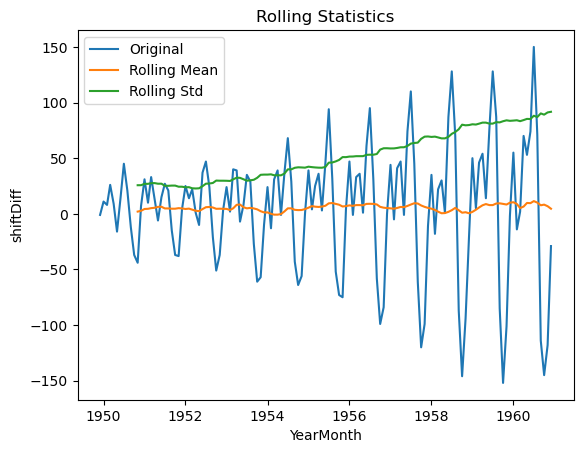

In [26]:
test_stationary(airP.dropna(),'shiftDiff')

In [40]:
# For acf-Differnecing of 2 and 12
airP['seconddiff']=airP9'passengers'].diff(2)
airP['Diff12']=airP'['passengers'].diff(12)

SyntaxError: unmatched ']' (128288892.py, line 2)

In [41]:
#Train-test split
train_size=int(len(airP)*0.7)
train=airP.nkhyt[l;iloc[train_size]
test=airP.iloc[train_size:]

IndentationError: unexpected indent (4278811637.py, line 3)

In [ ]:
#Arima model
model_arima=ARIMA(train['passengers'],order=(1,2,1))
model_arima_fir=mo0del_arima.fit()
arima_prad=model_arima_fit.predict(start=len(train),
                                   end=len(airP)-1)

In [ ]:
#Sarimax model
#To calcuate P AND q FOR sarimax
airP['diff_combined']=airP['passengers'].diff(2).diff(12)
plot_pacf(airP['dif_combined']
          plot_acf(airP['diff_combined'].dropna(),laga=500

In [ ]:
#ADD SARIMAX prediction to data frame
airP['sarimaxPred']=np.nan
airP.iloc[train_size:,airP.coloumns.fet_loc('sarimaxPred')]
=sarimax_pred.values
    print(airP.tail(20))

In [43]:
#Plot predictions
plt.figure(figsize=(10,5))
snas.lineplot9x=airP.index,y=airP['passengers'],
label='Actual passengers')
sns.lineplot(x=airP.index,y=airP('arimapred')

SyntaxError: unmatched ')' (153548806.py, line 4)